# Paradoja del Cumpleaños

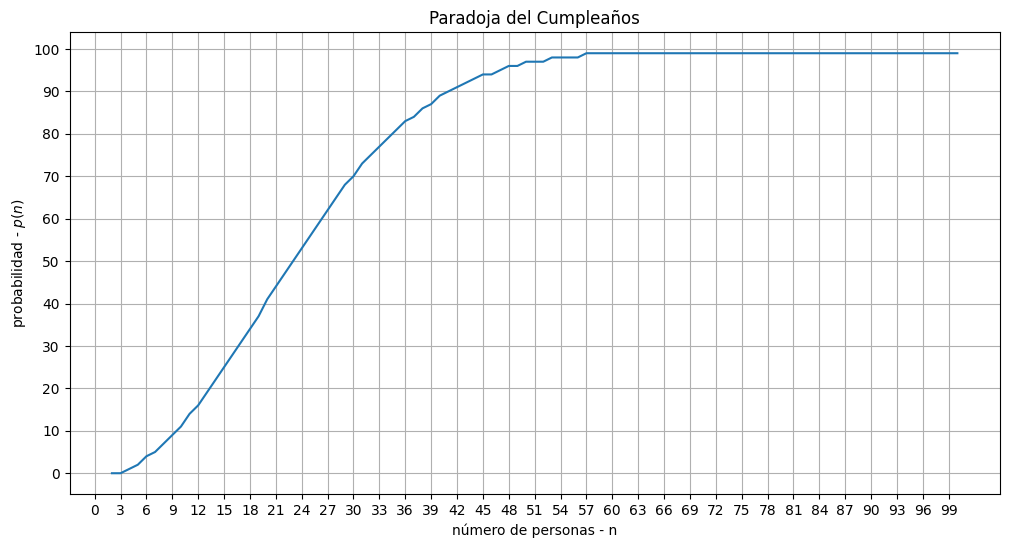

In [24]:
import numpy as np
import matplotlib.pyplot as plt

def prob_cump (n):
  prob = 1                  #probabilidad de que n personas no cumplan años el mismo dia
  for i in range(n):
    prob = prob*(1-i/365)
  return (1-prob)*100       #probabilidad de que n personas cumplan años el mismo dia

num_per = np.arange(2,101,1)
prob = np.zeros_like(num_per)
for i in range(len(num_per)):
  prob[i] = prob_cump(num_per[i])

#Gráficamos número de personas - n vs probabilidad - p(n)
plt.figure(figsize=(12,6))
plt.plot(num_per,prob)
plt.title(f'Paradoja del Cumpleaños')
plt.xlabel(f'número de personas - n')
plt.ylabel(f'probabilidad - $p(n)$')
plt.grid()

#Añadimos más puntos en la gráfica
plt.xticks(np.arange(0, 101, 3))
plt.yticks(np.arange(0, 101, 10))

plt.show()

In [25]:
print(f'La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 23 personas es p(23)={prob_cump(23)}')

La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 23 personas es p(23)=50.72972343239854


In [26]:
print(f'La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 41 personas es p(41)={prob_cump(41)}')

La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 41 personas es p(41)=90.31516114817354


# Generar Secuencias de ADN Aleatorias

In [27]:
!pip install biopython

In [28]:
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
import random as rand

# Por defecto las funciones aceptan y retornan tipo Seq a menos que se especifique tipo = "str"

def generar_adn(longitud, tipo=""):
    sec_adn = list()
    bases = ['A','C','G','T']
    for i in range(longitud):
        sec_adn.append(rand.choice(bases))     # Selecciona aleatoriamente una base
    if tipo == "str":
        return ''.join(sec_adn)
    return Seq(''.join(sec_adn))

In [29]:
print(f'La secuencia de ADN generada es: {generar_adn(50)}')

La secuencia de ADN generada es: GATCAATTCGCGCGTCCAGCCCTTAACCTCTCTGAGTGGTTTCATTATAC


# Generar Secuencias de ADN Mutadas

In [30]:
import random as rand

def mutar_adn(secuencia, tasa_mutacion, tipo=""):      #0 <= tasa_mutacion <= 1
    bases = ['A', 'C', 'G', 'T']
    secuencia_mutada = list(secuencia)
    for i in range(len(secuencia_mutada)):
        if rand.random() < tasa_mutacion:     #Condición de para mutar una base de la secuencia
            # Seleccionamos las bases distintas para hacer la mutación
            opciones = [b for b in bases if b != secuencia_mutada[i]]
            secuencia_mutada[i] = rand.choice(opciones)
    if tipo == "str":
        return ''.join(secuencia_mutada)
    return Seq(''.join(secuencia_mutada))

In [31]:
g = generar_adn(50)
print(f'La secuencia de ADN generada es: {g}')
g_mutada = mutar_adn(g,0.1)
print(f'La secuencia de ADN mutada a un {0.1*100}% es: {g_mutada}')

La secuencia de ADN generada es: CAGGCCTGATGTTAAACGGCCTTAGCTAAAGATCGCTCTTTTCACTTATC
La secuencia de ADN mutada a un 10.0% es: CAGGTAGGATGTTAAACCTCCTTAGAGAAAGATCGCTCTTTTCTTGTATC


# Construcción del Conjunto de los k-meros

In [32]:
def k_meros(secuencia, k, tipo=""): # 1 <= k <= len(secuencia)
  kmeros= set()
  if k > len(secuencia):
    return None
  elif k == len(secuencia):
    kmeros.add(str(secuencia)) if tipo == "str" else kmeros.add(secuencia)
    return kmeros
  else:
    for i in range(len(secuencia) - (k - 1)):
      kmeros.add(str(secuencia[i:i+k])) if tipo == "str" else kmeros.add(secuencia[i:i+k])
    return kmeros

In [33]:
g = generar_adn(30)
print(f'La secuencia de ADN generada es g = {g}')
#construimos el conjunto de los k-meros de g
k=15
kmeros = k_meros(g,k)
print(f'El conjunto de {k}-meros de g es:')
for k in kmeros:
  print(k)

La secuencia de ADN generada es g = ATGCTGCTCTGCCGCCGAGTGGGTCACGGT
El conjunto de 15-meros de g es:
CTGCTCTGCCGCCGA
GCCGCCGAGTGGGTC
TGCCGCCGAGTGGGT
TCTGCCGCCGAGTGG
CCGCCGAGTGGGTCA
TGCTGCTCTGCCGCC
CGCCGAGTGGGTCAC
CGAGTGGGTCACGGT
TGCTCTGCCGCCGAG
ATGCTGCTCTGCCGC
GCTGCTCTGCCGCCG
CTGCCGCCGAGTGGG
CCGAGTGGGTCACGG
GCTCTGCCGCCGAGT
GCCGAGTGGGTCACG
CTCTGCCGCCGAGTG


# Construcción de la Matriz de Representación

In [34]:
import numpy as np

def matrizRepresentacion (conjuntos):
  elementos = set()
  for s in conjuntos:
    elementos.update(s)

  M = np.zeros((len(elementos),len(conjuntos)))
  row = 0
  for i in elementos:
    column = 0
    for s in conjuntos:
      if i in s:
        M[row,column] = 1
      column += 1
    row += 1
  return [elementos,M]

In [35]:
# Generamos secuencias de ADN aleatorias

adn_1 = generar_adn(20)
adn_2 = generar_adn(20)
adn_3 = generar_adn(20)
adn_4 = generar_adn(20)

j=1
for i in [adn_1,adn_2,adn_3,adn_4]:
  print(f'Decuencia de ADN generada adn_{j} = {i}')
  j += 1

Decuencia de ADN generada adn_1 = TCTATGGAATGGTTTGAGGA
Decuencia de ADN generada adn_2 = CAAGCGTGCCCGGTGCCAGG
Decuencia de ADN generada adn_3 = CTCTGAACGCAATCACTAAC
Decuencia de ADN generada adn_4 = CGTGACTGGAGTCCAATTCC


# Aplicación a datos reales

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
fasta = '/content/drive/MyDrive/sequences.fasta'
csv = '/content/drive/MyDrive/sequences.csv'

In [38]:
import pandas as pd

# Importamos la información obtenida del NCBI que detalla
# las características de cada secuenciación completa del
# SARS-CoV-2 como la especie, variante, origen de la muestra, etc.

df = pd.read_csv(csv)
print(df.dtypes)

Accession                  object
Organism_Name              object
Species                    object
Pangolin                   object
PangoVersions              object
Genotype                  float64
Isolate_Strain             object
GenBank_Title              object
Length                      int64
Nuc_Completeness           object
Geo_Location               object
Country                    object
Host                       object
Tissue_Specimen_Source     object
Collection_Date            object
Release_Date               object
Molecule_Type              object
dtype: object


In [39]:
# Le cambiamos el tipo a la fecha de recolección y de liberación
df["Collection_Date"] = pd.to_datetime(df["Collection_Date"], format="mixed")
df["Release_Date"] = pd.to_datetime(df["Release_Date"], format="mixed")

In [40]:
# Las secuenciaciones corresponden a diferentes variantes (Pangolin)
# de las cuales existen múltiples registros

print(df["Pangolin"].value_counts())

Pangolin
BA.1.1       1350
AY.25        1346
P.1.15       1125
C.37          793
P.1           713
             ... 
B.1.351         1
BA.2.86.1       1
AY.23           1
B.41            1
B.11            1
Name: count, Length: 269, dtype: int64


In [41]:
# Las secuencias propiamente las encontramos en el
# archivo sequences.fasta

for record in SeqIO.parse(fasta, "fasta"):
  print(record.id)
  print(repr(record.seq))
  print(len(record.seq))

# Es de resaltar que la longitud de las secuencias es de alrededor de 30000 bases cada una

Se han truncado las últimas 5000 líneas del flujo de salida.
Seq('AACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGG...ACC')
29787
OZ061873.1
Seq('ACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGC...TCC')
29798
OZ061874.1
Seq('ACCAACCAACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATC...TCC')
29787
OZ061875.1
Seq('AGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGCTGTCACTCGGCTGCAT...TCC')
29752
OZ061876.1
Seq('CAACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTG...ACC')
29795
OZ061877.1
Seq('ACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGC...AAA')
29833
OZ061878.1
Seq('ACCAACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTG...ACC')
29797
OZ061879.1
Seq('ACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGC...TCC')
29795
OZ061880.1
Seq('ACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGC...TCC')
29786
OZ061881.1
Seq('CTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTGTGTGGCT...TCC')
29792
OZ061882.1
Seq('TTCCCAGGTAACAAACCAACCAACTTTCGATCTCTTGTAGATCTGTTCTCTAAA...ACC')
29815
OZ061883.1
Seq(

In [42]:
# donde record.id corresponde al atributo Accession de
# la tabla, el cual podemos utilizar como clave primaria
# cuando decidamos contrastar las mutaciones entre variantes

df["Accession"].is_unique

True

In [43]:
# Filtramos por la primera aparicion de cada nueva variante

df.sort_values("Collection_Date").groupby("Pangolin").head(1)

,Accession,Organism_Name,Species,Pangolin,PangoVersions,Genotype,Isolate_Strain,GenBank_Title,Length,Nuc_Completeness,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Molecule_Type
0,NC_045512,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,B,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,Wuhan-Hu-1,Severe acute respiratory syndrome coronavirus ...,29903,complete,China,China,Homo sapiens,NaN,2019-12-01,2020-01-13,ssRNA(+)
12409,MN938384,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,A,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,2019-nCoV_HKU-SZ-002a_2020,Severe acute respiratory syndrome coronavirus ...,29838,complete,China: Shenzhen,China,Homo sapiens,oronasopharynx,2020-01-10,2020-01-24,ssRNA(+)
12345,MT159709,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,B.5,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,Cruise-CDC-3054616-001,Severe acute respiratory syndrome coronavirus ...,29882,complete,USA,USA,Homo sapiens,oronasopharynx,2020-02-20,2020-03-09,ssRNA(+)
12361,MT152824,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,A.1,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,WA2,Severe acute respiratory syndrome coronavirus ...,29878,complete,"USA: Snohomish County, WA",USA,Homo sapiens,oronasopharynx,2020-02-24,2020-03-05,ssRNA(+)
12335,MT163716,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,B.41,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,WA3-UW1,Severe acute respiratory syndrome coronavirus ...,29903,complete,USA: WA,USA,Homo sapiens,NaN,2020-02-27,2020-03-10,ssRNA(+)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2488,OZ074756,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,XBB.1.18.1,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,INEI125517,Severe acute respiratory syndrome coronavirus ...,29732,complete,Argentina:Chaco,Argentina,Homo sapiens,NaN,2023-04-10,2024-06-01,ssRNA(+)
2568,OZ074836,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,XBB.1.5.77,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,INEI125520,Severe acute respiratory syndrome coronavirus ...,29721,complete,Argentina:Chaco,Argentina,Homo sapiens,NaN,2023-04-11,2024-06-01,ssRNA(+)
2457,OZ074725,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,FL.3,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,INEI125503,Severe acute respiratory syndrome coronavirus ...,29761,complete,Argentina:Ciudad Autonoma de Buenos Aires,Argentina,Homo sapiens,NaN,2023-04-13,2024-06-01,ssRNA(+)
12320,OZ026640,Severe acute respiratory syndrome coronavirus 2,Betacoronavirus pandemicum,BA.2.86.1,4.3.4/1.37.1/v0.1.12/0.3.19/0.6.6,NaN,RNA,Severe acute respiratory syndrome coronavirus ...,29819,complete,Slovakia,Slovakia,Homo sapiens,NaN,2023-12-04,2024-04-04,ssRNA(+)


In [44]:
# Nos quedamos con unas pocas para el análisis

g_id = df.sort_values("Collection_Date").groupby("Pangolin").head(1)["Accession"].head(5).array
print(g_id)
g_id = set(g_id)
g = [sec_record.seq for sec_record in SeqIO.parse(fasta, "fasta") if sec_record.id.split(".")[0] in g_id]
for s in g:
  print(repr(s))

<NumpyExtensionArray>
['NC_045512', 'MN938384', 'MT159709', 'MT152824', 'MT163716']
Length: 5, dtype: object
Seq('ATTAAAGGTTTATACCTTCCCAGGTAACAAACCAACCAACTTTCGATCTCTTGT...AAA')
Seq('TTTAAAGGTTTATACCTTCCCAGGTAACAAACCATTCAACTTTCGATCTCTTGT...AAA')
Seq('ATTAAAGGTTTATACCTTCCCAGGTAACAAACCAACCAACTTTCGATCTCTTGT...AAA')
Seq('TAAAGGTTTATACCTTCCCAGGTAACAAACCAACCAACTTTCGATCTCTTGTAG...AAA')
Seq('CAACCAACTTTCGATCTCTTGTAGATCTGTTCTCTAAACGAACTTTAAAATCTG...GAC')


In [45]:
# Obtenemos los k-meros

k = 13
S = [k_meros(seq, k) for seq in g]

In [46]:
# Calculamos la matriz de representación

elementos, M = matrizRepresentacion(S)

j=0
for i in elementos:
  print(f'{M[j]}')
  j += 1

Se han truncado las últimas 5000 líneas del flujo de salida.
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1.]
[1. 